# ParFlow Short Course: Box domain analysis

### Problem Description
This script illustrates how to open up results from a ParFlow run and do some simple analysis and plotting. 


In [7]:
# Import the ParFlow package
from parflow import Run
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
from parflow.tools.fs import mkdir, cp, chdir, get_absolute_path, rm, exists
from parflow.tools.io import read_pfb
import parflow.tools.hydrology as hydro

# Import functions for plotting
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../utils")))
from plots import plot_domain, plot_subsurface_storage, plot_water_balance


#Pick one of your previous runs to look at 
pf_runname  = "Test2"
base = os.path.join(os.getcwd(), "box_runs", pf_runname )

# Import run information from pfidb
domain_example = Run.from_definition(os.path.join(base, f"{pf_runname}.pfidb"))

# 1. Looking at some gridded outputs

Option 1 ues the plotting function included in this repo to quickly plot up any field like this

nx = 20, ny = 1, nz = 10, nt = 101
dx = 100.0, dy = 2.0, dz = [10.  10.  10.  10.   5.   1.   1.   0.6  0.3  0.1]
vmin: 0.28374782761443423, vmax: 0.9155417527999328


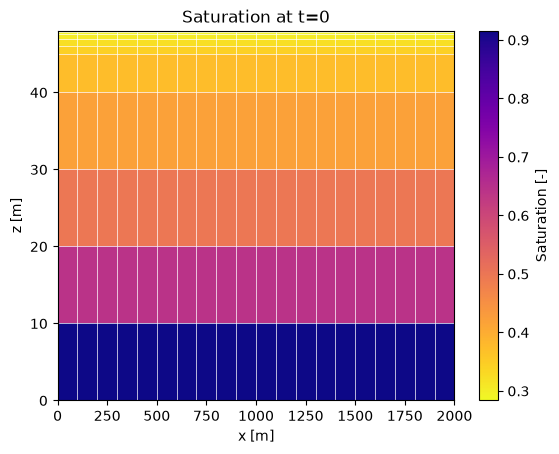

nx = 20, ny = 1, nz = 10, nt = 101
dx = 100.0, dy = 2.0, dz = [10.  10.  10.  10.   5.   1.   1.   0.6  0.3  0.1]
vmin: -9.5, vmax: -0.5


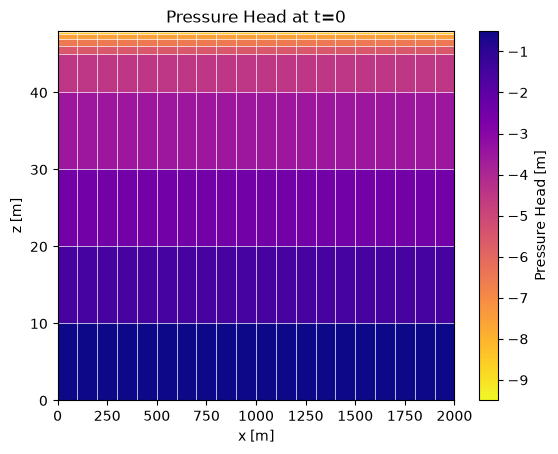

nx = 20, ny = 1, nz = 10, nt = 101
dx = 100.0, dy = 2.0, dz = [10.  10.  10.  10.   5.   1.   1.   0.6  0.3  0.1]
vmin: 0.3093661839051616, vmax: 0.9176839890816535
nx = 20, ny = 1, nz = 10, nt = 101
dx = 100.0, dy = 2.0, dz = [10.  10.  10.  10.   5.   1.   1.   0.6  0.3  0.1]
vmin: -7.2461990736735356, vmax: -0.4924924495981092
nx = 20, ny = 1, nz = 10, nt = 101
dx = 100.0, dy = 2.0, dz = [10.  10.  10.  10.   5.   1.   1.   0.6  0.3  0.1]
vmin: 0.34407057006905717, vmax: 0.979243321153771
nx = 20, ny = 1, nz = 10, nt = 101
dx = 100.0, dy = 2.0, dz = [10.  10.  10.  10.   5.   1.   1.   0.6  0.3  0.1]
vmin: -5.462048015560844, vmax: -0.23234341518382148
nx = 20, ny = 1, nz = 10, nt = 101
dx = 100.0, dy = 2.0, dz = [10.  10.  10.  10.   5.   1.   1.   0.6  0.3  0.1]
vmin: 0.4997185752140629, vmax: 0.9880291646158039
nx = 20, ny = 1, nz = 10, nt = 101
dx = 100.0, dy = 2.0, dz = [10.  10.  10.  10.   5.   1.   1.   0.6  0.3  0.1]
vmin: -2.4747669642641905, vmax: -0.17496419202517507


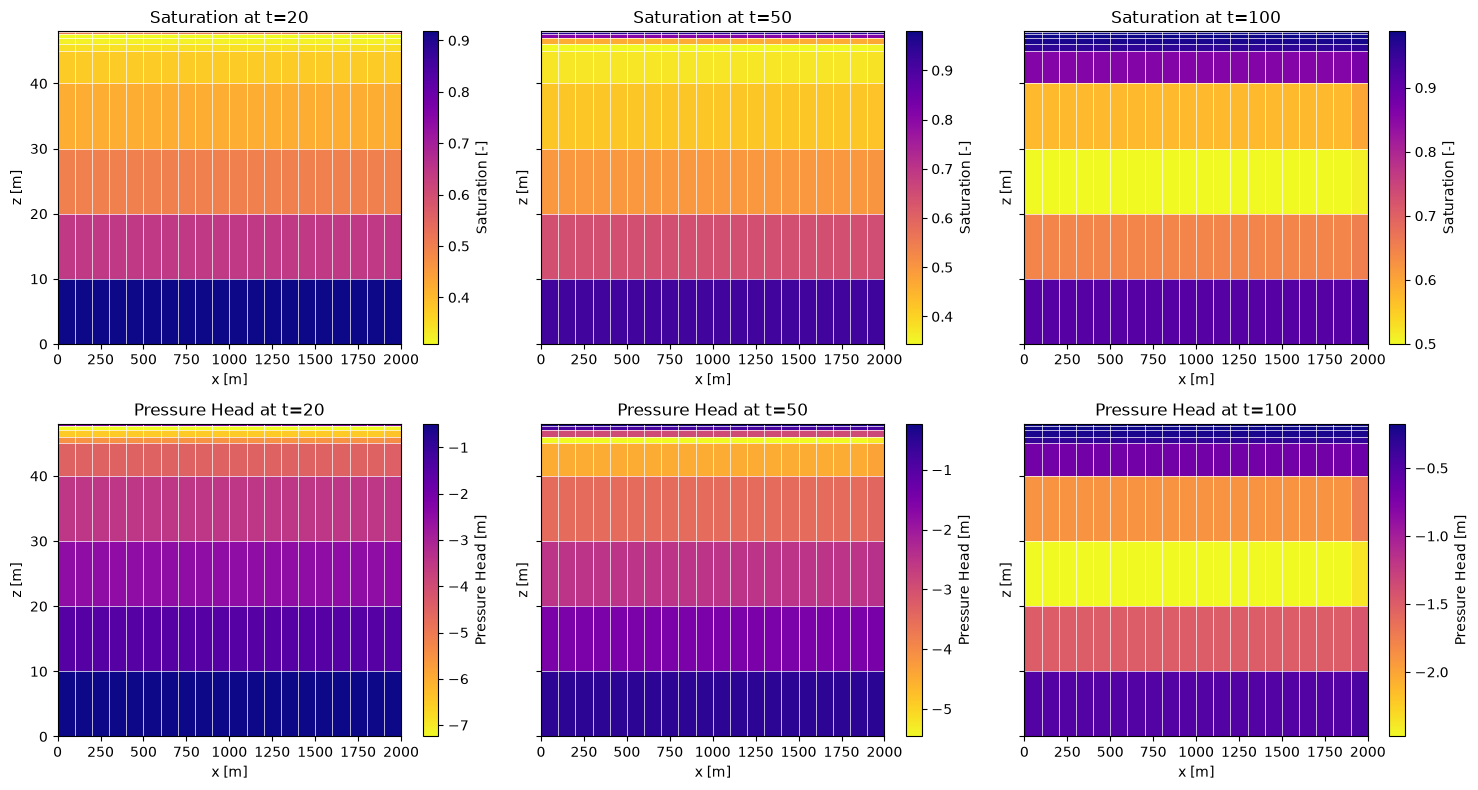

In [8]:
# Call plotting function for saturation and pressure
#base = os.path.join(os.getcwd(), "output")
plot_domain(base, "satur", timestep=0, run_name=pf_runname)
plot_domain(base, "press", timestep=0, run_name=pf_runname)

# Plot saturation and pressure at multiple timesteps in one figure
timesteps = [20, 50, 100]
fig, axes = plt.subplots(2, len(timesteps), figsize=(15, 8), sharey="row")

for column, t in enumerate(timesteps):
    plot_domain(base, "satur", timestep=t, run_name=pf_runname, ax=axes[0, column])
    plot_domain(base, "press", timestep=t, run_name=pf_runname, ax=axes[1, column])

fig.tight_layout()
plt.show()

## Option 2 read the file and plot it yourself

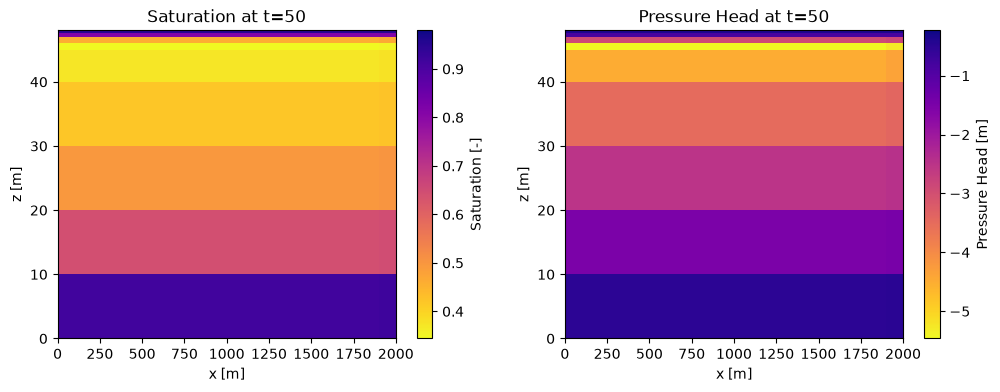

In [9]:
# Read one saturation file and one pressure file (timestep 50)
satur = read_pfb(os.path.join(base, f"{pf_runname}.out.satur.00050.pfb"))
press = read_pfb(os.path.join(base, f"{pf_runname}.out.press.00050.pfb"))

# ParFlow arrays are (z, y, x). This domain has a single y row, so take it out to get a 2D (z, x) array
satur = satur[:, 0, :]
press = press[:, 0, :]

# Negative saturation values mark inactive cells, so hide them
satur[satur < 0] = np.nan

# Build the cell edges so the plot is in meters and respects the variable layer thickness
grid = domain_example.ComputationalGrid
keys = domain_example.to_dict()

# Layer thickness = DZ x dzScale for each layer (layers are not all the same thickness)
dz = np.array([grid.DZ * keys.get(f"Cell.{k}.dzScale.Value", 1.0) for k in range(grid.NZ)])

x_edges = np.arange(grid.NX + 1) * grid.DX      # one more edge than cells
z_edges = np.concatenate(([0.0], np.cumsum(dz)))  # cumulative layer thickness from the bottom

# Plot the two fields side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

im1 = ax1.pcolormesh(x_edges, z_edges, satur, cmap="plasma_r")
ax1.set_title("Saturation at t=50")
fig.colorbar(im1, ax=ax1, label="Saturation [-]")

im2 = ax2.pcolormesh(x_edges, z_edges, press, cmap="plasma_r")
ax2.set_title("Pressure Head at t=50")
fig.colorbar(im2, ax=ax2, label="Pressure Head [m]")

for ax in (ax1, ax2):
    ax.set_xlabel("x [m]")
    ax.set_ylabel("z [m]")

plt.show()

# 2. Calculating a water balance

The data accessor helps you access outputs from your run

In [10]:
data = domain_example.data_accessor

#For your refrence here is some information about what is contained in data
type(data)  # What kind of object it is
#[name for name in dir(data) if not name.startswith("_")] 

parflow.tools.io.DataAccessor

We'll use this and the keys we set to get static properties of the domain we need for calcualations

In [11]:
#First some dimensions
nt = len(data.times)
dx, dy = data.dx, data.dy
dt = domain_example.TimeStep.Value

# Layer thickness (bottom to top). ParFlow only applies the dzScale values when
# Solver.Nonlinear.VariableDz is True, otherwise every layer is ComputationalGrid.DZ thick
keys = domain_example.to_dict()
if keys.get("Solver.Nonlinear.VariableDz", False):
    dz = np.array([keys["ComputationalGrid.DZ"] * keys[f"Cell.{k}.dzScale.Value"]
                   for k in range(data.shape[0])])
else:
    dz = np.full(data.shape[0], keys["ComputationalGrid.DZ"])
print(dz)

#Now we'll get static gridded properties
porosity = data.computed_porosity
specific_storage = data.specific_storage
mask = data.mask
surface_area = np.sum(mask[-1] > 0) * dx * dy
recharge_flux = -keys["Patch.z_upper.BCPressure.alltime.Value"]

# Surface area of active cells and timestep length, used for the recharge volume
surface_area = np.sum(mask[-1] > 0) * dx * dy
dt = domain_example.TimeStep.Value

# Slopes and Manning's n for overland flow, look for an ouptu file
# if not fall back to the constants in the run definition if no output file exists
ny, nx = data.shape[1], data.shape[2]
def output_or_constant(name, key):
    try:
        return getattr(data, name)
    except FileNotFoundError:
        return np.full((1, ny, nx), float(keys[key]))

slopex = output_or_constant("slope_x", "TopoSlopesX.Geom.domain.Value")
slopey = output_or_constant("slope_y", "TopoSlopesY.Geom.domain.Value")
mannings = output_or_constant("mannings", "Mannings.Geom.domain.Value")

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Now we calcualte the terms we need for the water balance

In [12]:
# Use hydro tools and ParFlow's output fluxes to calculate the water balance components
surface_storage = np.zeros(nt)
subsurface_storage = np.zeros(nt)
overland_out = np.zeros(nt)
recharge_in = np.zeros(nt)
x_upper_in = np.zeros(nt)

for t in range(nt):
    data.time = t
    pressure, saturation = data.pressure, data.saturation

    # ParFlow's accumulation term is porosity*S + Ss*S*p everywhere, including where p < 0.
    # hydro.calculate_subsurface_storage zeroes the compressible term for p < 0, which leaves
    # a small (~0.1%) closure error, so we compute the storage the way ParFlow does.
    cell_volume = dz[:, None, None] * dx * dy
    subsurface_storage[t] = np.sum(
        (porosity * saturation + specific_storage * saturation * pressure) * cell_volume * (mask > 0))
    surface_storage[t] = np.sum(
        hydro.calculate_surface_storage(pressure, dx, dy, mask=mask))
    # Note that this function just calculates the overland flow out of the domain. There is a
    # gridded function option if you want to see overland flow everywhere
    overland_out[t] = hydro.calculate_overland_flow(pressure, slopex, slopey, mannings, dx, dy,
        flow_method="OverlandFlow", mask=mask)
    recharge_in[t] = recharge_flux * surface_area * dt

    # ParFlow writes the Darcy flux on every x-face [L/T] (shape nz, ny, nx+1).
    # The last face is the x_upper constant head boundary. Flux is + in +x, so inflow is -vx
    vx = read_pfb(os.path.join(base, f"{pf_runname}.out.velx.{t:05d}.pfb"))
    x_upper_in[t] = -np.sum(vx[:, :, -1] * dy * dz[:, None]) * dt


# To check the water balance we'll calculate the change in storage
d_subsurface = np.diff(subsurface_storage, prepend=subsurface_storage[0])
d_surface = np.diff(surface_storage, prepend=surface_storage[0])
outflow = overland_out * dt

# Close the balance: change in storage = inflows - outflows (skip t=0, no previous step)
imbalance = (d_subsurface + d_surface) - (recharge_in + x_upper_in - outflow)
print(f"Total recharge in:        {recharge_in[1:].sum():10.3f} m^3")
print(f"Total x_upper net inflow: {x_upper_in[1:].sum():10.3f} m^3")
print(f"Total overland outflow:   {outflow[1:].sum():10.3f} m^3")
print(f"Total change in storage:  {(d_subsurface + d_surface)[1:].sum():10.3f} m^3")
print(f"Total imbalance:          {imbalance[1:].sum():10.3f} m^3")

Total recharge in:          4000.000 m^3
Total x_upper net inflow:      3.696 m^3
Total overland outflow:        0.000 m^3
Total change in storage:    4003.696 m^3
Total imbalance:               0.000 m^3


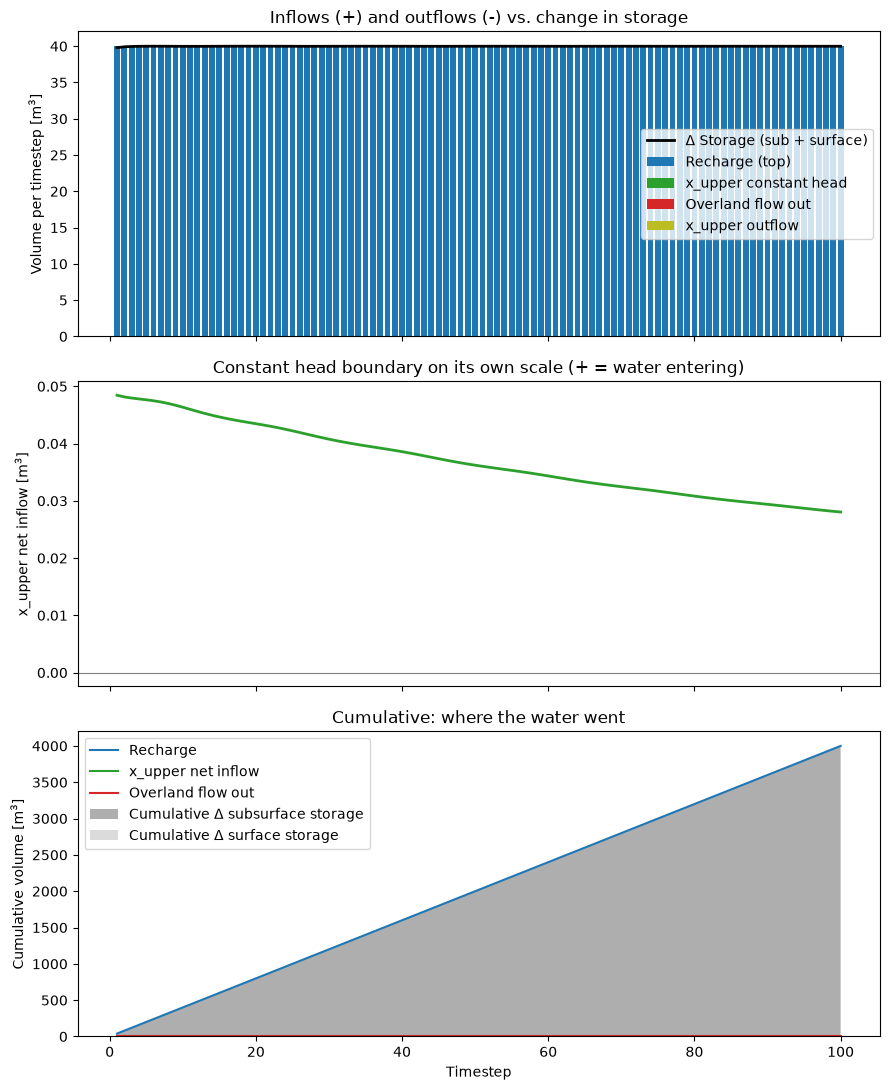

In [26]:
# Skip the first timestep for plotting: it has no previous step, so its change in storage is zero
sl = slice(1, None)
t_axis = np.arange(nt)[sl]
recharge_p, x_upper_p, outflow_p = recharge_in[sl], x_upper_in[sl], outflow[sl]
d_sub_p, d_surf_p = d_subsurface[sl], d_surface[sl]
x_in, x_out = np.clip(x_upper_p, 0, None), np.clip(x_upper_p, None, 0)
d_storage = d_sub_p + d_surf_p

fig, axs = plt.subplots(3, 1, figsize=(9, 11), sharex=True)

# 1) Where the water comes from and goes: inflows stacked up, outflows stacked down
axs[0].bar(t_axis, recharge_p, color="tab:blue", label="Recharge (top)")
axs[0].bar(t_axis, x_in, bottom=recharge_p, color="tab:green", label="x_upper constant head")
axs[0].bar(t_axis, -outflow_p, color="tab:red", label="Overland flow out")
axs[0].bar(t_axis, x_out, bottom=-outflow_p, color="tab:olive", label="x_upper outflow")
axs[0].plot(t_axis, d_storage, "k-", lw=2, label="Δ Storage (sub + surface)")
axs[0].set_ylabel("Volume per timestep [m$^3$]")
axs[0].set_title("Inflows (+) and outflows (-) vs. change in storage")
axs[0].legend(loc="center right")

# 2) The side boundary is small next to recharge, so look at it on its own scale
axs[1].plot(t_axis, x_upper_p, color="tab:green", lw=2)
axs[1].axhline(0, color="gray", lw=0.8)
axs[1].set_ylabel("x_upper net inflow [m$^3$]")
axs[1].set_title("Constant head boundary on its own scale (+ = water entering)")

# 3) Cumulative volumes
axs[2].plot(t_axis, np.cumsum(recharge_p), color="tab:blue", label="Recharge")
axs[2].plot(t_axis, np.cumsum(x_upper_p), color="tab:green", label="x_upper net inflow")
axs[2].plot(t_axis, -np.cumsum(outflow_p), color="tab:red", label="Overland flow out")
axs[2].stackplot(t_axis, np.cumsum(d_sub_p), np.cumsum(d_surf_p),
                 colors=["0.55", "0.8"], alpha=0.7,
                 labels=["Cumulative Δ subsurface storage", "Cumulative Δ surface storage"])
axs[2].set_xlabel("Timestep")
axs[2].set_ylabel("Cumulative volume [m$^3$]")
axs[2].set_title("Cumulative: where the water went")
axs[2].legend(loc="upper left")

plt.tight_layout()
plt.show()